<a href="https://colab.research.google.com/github/2303a51210/quantum_computing_project/blob/main/QC_15_Q.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
import pandas as pd

train = pd.read_csv('train.csv')

print(train.head())

   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel780  pixel781  pixel782  pixel783  
0         0         0         

In [ ]:
print("Dataset shape:", train.shape)

Dataset shape: (42000, 785)


In [ ]:
print("Total Images:", len(train))

print("Total Columns:", len(train.columns))

print("Column Names:")
print(train.columns[:10])

print("Labels:")
print(train['label'].unique())

Total Images: 42000
Total Columns: 785
Column Names:
Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8'],
      dtype='object')
Labels:
[1 0 4 7 3 5 8 9 2 6]


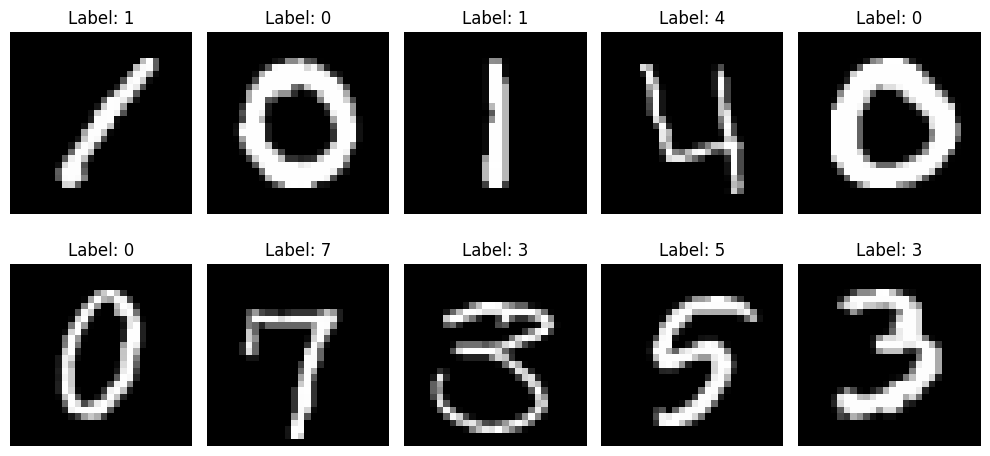

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = train.iloc[i, 1:].values.reshape(28, 28)

    plt.imshow(image, cmap='gray')
    plt.title("Label: " + str(train.iloc[i, 0]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Separate labels and pixel values
X = train.drop('label', axis=1).values
y = train['label'].values

# Normalize pixel values
X = X / 255.0

print("Image data shape:", X.shape)
print("Label data shape:", y.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Image data shape: (42000, 784)
Label data shape: (42000,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (33600, 784)
Testing images: (8400, 784)
Training labels: (33600,)
Testing labels: (8400,)


In [ ]:
from sklearn.decomposition import PCA

# Reduce 784 features to 4 features
pca = PCA(n_components=4)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("Reduced features:", X_train_pca.shape[1])

print("Training data:", X_train_pca.shape)
print("Testing data:", X_test_pca.shape)

print("Explained variance:", pca.explained_variance_ratio_.sum())


Original features: 784
Reduced features: 4
Training data: (33600, 4)
Testing data: (8400, 4)
Explained variance: 0.28415002311891796


In [ ]:
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 102.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 79.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]


In [ ]:
import qiskit

print("Qiskit version:", qiskit.__version__)
print("Qiskit installed successfully!")

Qiskit version: 2.6.2
Qiskit installed successfully!


In [ ]:
from qiskit import QuantumCircuit

# Create a circuit with 4 qubits
qc = QuantumCircuit(4)

# Apply Hadamard gate
for i in range(4):
    qc.h(i)

# Apply Rotation-Y gate
for i in range(4):
    qc.ry(0.5, i)

# Display circuit
print(qc.draw())

     ┌───┐┌─────────┐
q_0: ┤ H ├┤ Ry(0.5) ├
     ├───┤├─────────┤
q_1: ┤ H ├┤ Ry(0.5) ├
     ├───┤├─────────┤
q_2: ┤ H ├┤ Ry(0.5) ├
     ├───┤├─────────┤
q_3: ┤ H ├┤ Ry(0.5) ├
     └───┘└─────────┘


In [ ]:
from qiskit.circuit import ParameterVector

theta = ParameterVector('theta', 4)

qc = QuantumCircuit(4)

for i in range(4):
    qc.ry(theta[i], i)

for i in range(3):
    qc.cx(i, i + 1)

print(qc.draw())

     ┌──────────────┐               
q_0: ┤ Ry(theta[0]) ├──■────────────
     ├──────────────┤┌─┴─┐          
q_1: ┤ Ry(theta[1]) ├┤ X ├──■───────
     ├──────────────┤└───┘┌─┴─┐     
q_2: ┤ Ry(theta[2]) ├─────┤ X ├──■──
     ├──────────────┤     └───┘┌─┴─┐
q_3: ┤ Ry(theta[3]) ├──────────┤ X ├
     └──────────────┘          └───┘


In [ ]:
from qiskit import QuantumCircuit

def encode_data(features):

    circuit = QuantumCircuit(4)

    for i in range(4):
        angle = float(features[i])
        circuit.ry(angle, i)

    for i in range(3):
        circuit.cx(i, i + 1)

    return circuit

sample_circuit = encode_data(X_train_pca[0])

print(sample_circuit.draw())

     ┌─────────────┐                
q_0: ┤ Ry(0.62512) ├───■────────────
     ├─────────────┴┐┌─┴─┐          
q_1: ┤ Ry(-0.21659) ├┤ X ├──■───────
     └┬────────────┬┘└───┘┌─┴─┐     
q_2: ─┤ Ry(-1.401) ├──────┤ X ├──■──
     ┌┴────────────┤      └───┘┌─┴─┐
q_3: ┤ Ry(-1.7873) ├───────────┤ X ├
     └─────────────┘           └───┘


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_pca, y_train)

print("Classical model training completed!")

Classical model training completed!


In [ ]:
y_pred = model.predict(X_test_pca)

print("Predictions:", y_pred[:10])
print("Actual:", y_test[:10])

Predictions: [1 3 6 8 8 7 2 9 9 7]
Actual: [1 8 6 9 5 7 6 7 7 7]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print("Macro F1:",
      f1_score(y_test, y_pred, average='macro'))

print(classification_report(y_test, y_pred))

Accuracy: 0.5742857142857143
Balanced Accuracy: 0.5656382416066343
Macro F1: 0.5509658641157918
              precision    recall  f1-score   support

           0       0.76      0.82      0.79       827
           1       0.85      0.94      0.89       937
           2       0.54      0.54      0.54       835
           3       0.57      0.71      0.63       870
           4       0.57      0.61      0.59       814
           5       0.41      0.22      0.29       759
           6       0.59      0.62      0.60       827
           7       0.49      0.64      0.56       880
           8       0.40      0.35      0.37       813
           9       0.32      0.20      0.24       838

    accuracy                           0.57      8400
   macro avg       0.55      0.57      0.55      8400
weighted avg       0.55      0.57      0.56      8400



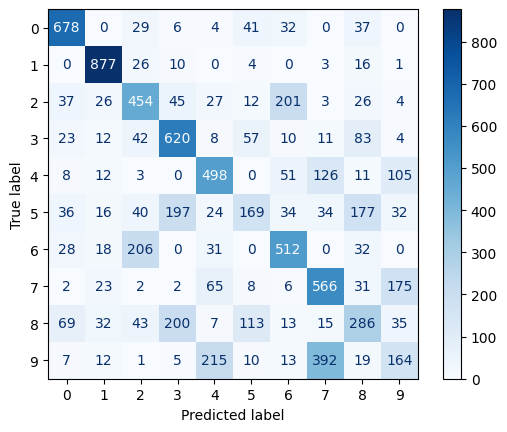

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

display.plot(cmap='Blues')
plt.show()

In [ ]:
!pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 81.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 25.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 64.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 52.0 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pennylane]


In [ ]:
import pennylane as qml

print("PennyLane version:", qml.__version__)
print("Quantum ML library installed successfully!")

PennyLane version: 0.45.1
Quantum ML library installed successfully!


In [ ]:
import pennylane as qml

# Create a 4-qubit quantum simulator
dev = qml.device("default.qubit", wires=4)

print("Quantum device created successfully!")
print("Number of qubits:", 4)

Quantum device created successfully!
Number of qubits: 4


In [ ]:
X_train_q = X_train_pca[:2000]
y_train_q = y_train[:2000]

X_test_q = X_test_pca[:500]
y_test_q = y_test[:500]

print("Quantum training data:", X_train_q.shape)
print("Quantum testing data:", X_test_q.shape)

Quantum training data: (2000, 4)
Quantum testing data: (500, 4)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))

X_train_q = scaler.fit_transform(X_train_q)
X_test_q = scaler.transform(X_test_q)

print("Quantum features scaled successfully!")
print(X_train_q[0])

Quantum features scaled successfully!
[-0.77861961 -0.1616807  -0.78125341 -0.85327862]


In [ ]:
import pennylane as qml
from pennylane import numpy as pnp

n_qubits = 4

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def quantum_circuit(inputs, weights):

    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)

    for i in range(n_qubits):
        qml.RY(weights[i], wires=i)

    for i in range(n_qubits - 1):
        qml.CNOT(wires=[i, i + 1])

    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weights = pnp.array([0.1, 0.2, 0.3, 0.4])

print("Quantum circuit output:")
print(quantum_circuit(X_train_q[0], weights))

Quantum circuit output:
[tensor(0.77843996, requires_grad=True), tensor(0.77786851, requires_grad=True), tensor(0.68951465, requires_grad=True), tensor(0.61988482, requires_grad=True)]


In [ ]:
print(qml.draw(quantum_circuit)(
    X_train_q[0], weights
))

0: ──RY(-0.78)──RY(0.10)─╭●───────┤  <Z>
1: ──RY(-0.16)──RY(0.20)─╰X─╭●────┤  <Z>
2: ──RY(-0.78)──RY(0.30)────╰X─╭●─┤  <Z>
3: ──RY(-0.85)──RY(0.40)───────╰X─┤  <Z>


In [ ]:
def quantum_classifier(inputs, weights, bias):
    # Obtain list of expectation values
    q_output = quantum_circuit(inputs, weights)

    # Convert the list of tensors into a single stacked Autograd tensor
    q_output_tensor = pnp.stack(q_output)

    return pnp.dot(q_output_tensor, weights) + bias

In [ ]:
def predict_digit(inputs, weights, bias):

    score = quantum_classifier(inputs, weights, bias)

    return score

In [ ]:
y_train_binary = (y_train_q >= 5).astype(float)
y_test_binary = (y_test_q >= 5).astype(float)

print("Binary training labels:", y_train_binary[:10])
print("Binary testing labels:", y_test_binary[:10])

Binary training labels: [0. 0. 1. 0. 0. 1. 1. 0. 1. 1.]
Binary testing labels: [0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
def loss_function(weights, bias, X, y):

    predictions = pnp.array([
        predict_digit(x, weights, bias)
        for x in X
    ])

    probabilities = (1 + pnp.tanh(predictions)) / 2

    epsilon = 1e-7

    loss = -pnp.mean(
        y * pnp.log(probabilities + epsilon)
        + (1-y) * pnp.log(1-probabilities + epsilon)
    )

    return loss

In [ ]:
# Redefining loss_function to use pnp.stack instead of pnp.array
def loss_function(weights, bias, X, y):
    predictions = pnp.stack([
        predict_digit(x, weights, bias)
        for x in X
    ])

    probabilities = (1 + pnp.tanh(predictions)) / 2
    epsilon = 1e-7

    loss = -pnp.mean(
        y * pnp.log(probabilities + epsilon)
        + (1-y) * pnp.log(1-probabilities + epsilon)
    )
    return loss

# Prepare data as PennyLane NumPy arrays
X_train_q_pnp = pnp.array(X_train_q, requires_grad=False)
y_train_binary_pnp = pnp.array(y_train_binary, requires_grad=False)

weights = pnp.array(
    [0.1, 0.2, 0.3, 0.4],
    requires_grad=True
)

bias = pnp.array(0.1, requires_grad=True)

optimizer = qml.GradientDescentOptimizer(stepsize=0.01)

epochs = 10

for epoch in range(epochs):
    weights, bias = optimizer.step(
        lambda w, b: loss_function(
            w, b, X_train_q_pnp[:100], y_train_binary_pnp[:100]
        ),
        weights,
        bias
    )

    current_loss = loss_function(
        weights, bias,
        X_train_q_pnp[:100], y_train_binary_pnp[:100]
    )

    print("Epoch:", epoch+1, "Loss:", float(current_loss))

Epoch: 1 Loss: 0.6925005392231192
Epoch: 2 Loss: 0.6923706571945776
Epoch: 3 Loss: 0.6922429108022311
Epoch: 4 Loss: 0.6921172564883412
Epoch: 5 Loss: 0.6919936515653647
Epoch: 6 Loss: 0.6918720541993963
Epoch: 7 Loss: 0.691752423393888
Epoch: 8 Loss: 0.6916347189736477
Epoch: 9 Loss: 0.6915189015691097
Epoch: 10 Loss: 0.691404932600876


In [ ]:
predictions = []

for x in X_test_q:

    output = predict_digit(x, weights, bias)

    probability = (1 + np.tanh(float(output))) / 2

    predictions.append(1 if probability >= 0.5 else 0)

predictions = np.array(predictions)

print("Quantum predictions:", predictions[:20])
print("Actual labels:", y_test_binary[:20])

Quantum predictions: [0 1 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1]
Actual labels: [0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1. 0. 0. 0.]


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("Accuracy:",
      accuracy_score(y_test_binary, predictions))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test_binary, predictions))

print("Macro F1:",
      f1_score(y_test_binary, predictions, average='macro'))

print(classification_report(y_test_binary, predictions))

Accuracy: 0.61
Balanced Accuracy: 0.5918679549114332
Macro F1: 0.5783437341878901
              precision    recall  f1-score   support

         0.0       0.63      0.37      0.46       230
         1.0       0.60      0.82      0.69       270

    accuracy                           0.61       500
   macro avg       0.62      0.59      0.58       500
weighted avg       0.62      0.61      0.59       500



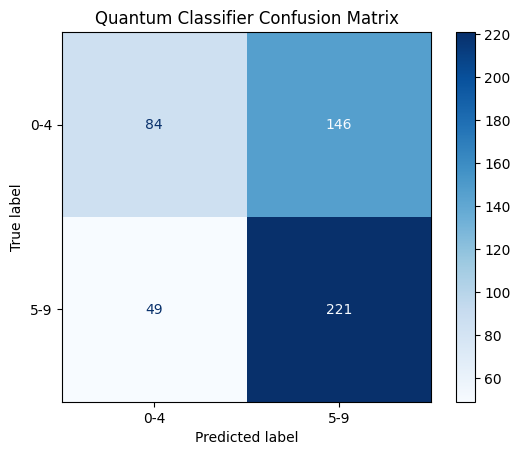

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test_binary, predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0-4", "5-9"]
).plot(cmap="Blues")

plt.title("Quantum Classifier Confusion Matrix")
plt.show()

In [ ]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 81.6 MB/s  0:00:00


In [ ]:
import qutip as qt

print("QuTiP version:", qt.__version__)
print("Quantum simulation library installed successfully!")

QuTiP version: 5.3.1
Quantum simulation library installed successfully!


In [ ]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

# Pauli operators
X_gate = qt.sigmax()
Y_gate = qt.sigmay()
Z_gate = qt.sigmaz()

# System Hamiltonian
omega = 0.0
H0 = (omega / 2) * Z_gate

# Control Hamiltonian
H1 = (1 / 2) * X_gate

print("Drift Hamiltonian:")
print(H0)

print("Control Hamiltonian:")
print(H1)

Drift Hamiltonian:
Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=CSR, isherm=True
Qobj data =
[[0. 0.]
 [0. 0.]]
Control Hamiltonian:
Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=CSR, isherm=True
Qobj data =
[[0.  0.5]
 [0.5 0. ]]


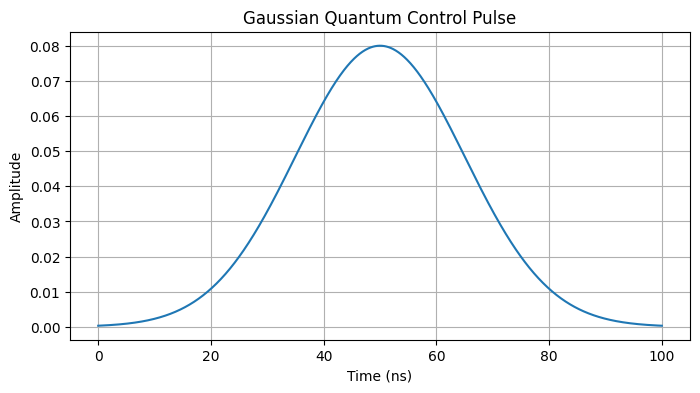

Pulse generated successfully!


In [ ]:
# Pulse settings
pulse_duration = 100.0  # nanoseconds
time_step = 0.1         # nanoseconds

tlist = np.arange(0, pulse_duration + time_step, time_step)

# Gaussian pulse parameters
sigma = 15.0
center = pulse_duration / 2
amplitude = 0.08

pulse = amplitude * np.exp(
    -((tlist - center) ** 2) / (2 * sigma ** 2)
)

plt.figure(figsize=(8, 4))
plt.plot(tlist, pulse)
plt.xlabel("Time (ns)")
plt.ylabel("Amplitude")
plt.title("Gaussian Quantum Control Pulse")
plt.grid()
plt.show()

print("Pulse generated successfully!")

In [ ]:
# Initial quantum state |0>
initial_state = qt.basis(2, 0)

# Time-dependent pulse coefficient
def pulse_function(t, args):
    return np.interp(t, tlist, pulse)

# Time-dependent Hamiltonian
H = [
    H0,
    [H1, pulse_function]
]

# Simulate quantum evolution
result = qt.sesolve(
    H,
    initial_state,
    tlist,
    e_ops=[X_gate, Y_gate, Z_gate]
)

print("Quantum state evolution completed!")

Quantum state evolution completed!


/usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


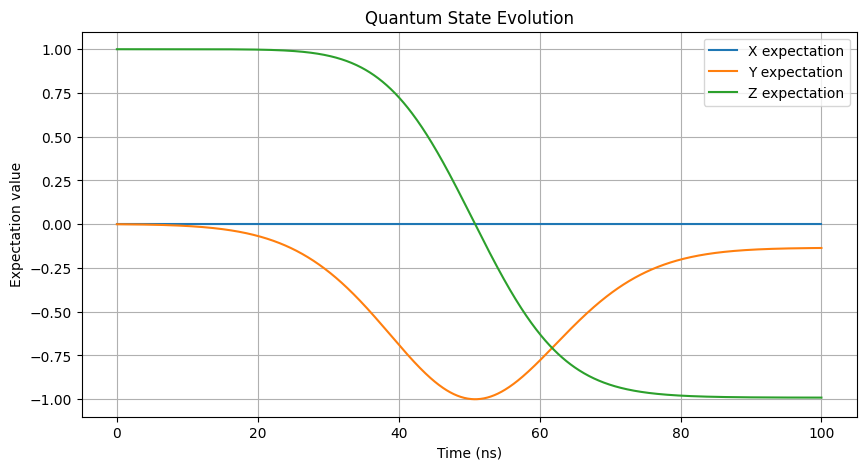

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(tlist, result.expect[0], label="X expectation")
plt.plot(tlist, result.expect[1], label="Y expectation")
plt.plot(tlist, result.expect[2], label="Z expectation")

plt.xlabel("Time (ns)")
plt.ylabel("Expectation value")
plt.title("Quantum State Evolution")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Simulate without e_ops to retain the state vectors
result_states = qt.sesolve(
    H,
    initial_state,
    tlist
)

final_state = result_states.states[-1]

# Probability of measuring |0> and |1>
prob_0 = abs(qt.expect(qt.ket2dm(qt.basis(2, 0)), final_state))
prob_1 = abs(qt.expect(qt.ket2dm(qt.basis(2, 1)), final_state))

print("Final Quantum State:")
print(final_state)

print("Probability of |0>:", prob_0)
print("Probability of |1>:", prob_1)
print("Total probability:", prob_0 + prob_1)

Final Quantum State:
Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.06805758+0.j        ]
 [0.        -0.99768139j]]
Probability of |0>: 0.0046318344847765805
Probability of |1>: 0.9953681655152236
Total probability: 1.0000000000000002


/usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


In [ ]:
pulse_start = tlist[0]
pulse_end = tlist[-1]

actual_duration = pulse_end - pulse_start

print("Pulse Duration:", actual_duration, "ns")

Pulse Duration: 100.0 ns


In [ ]:
# Frequency analysis using FFT
pulse_fft = np.fft.rfft(pulse)
frequencies = np.fft.rfftfreq(
    len(pulse),
    d=time_step
)

spectrum = np.abs(pulse_fft)

# Find -3 dB bandwidth
threshold = np.max(spectrum) / np.sqrt(2)

valid_frequencies = frequencies[spectrum >= threshold]

bandwidth = (
    valid_frequencies.max() - valid_frequencies.min()
    if len(valid_frequencies) > 0 else 0
)

print("Estimated Pulse Bandwidth:", bandwidth, "GHz")

Estimated Pulse Bandwidth: 0.0 GHz


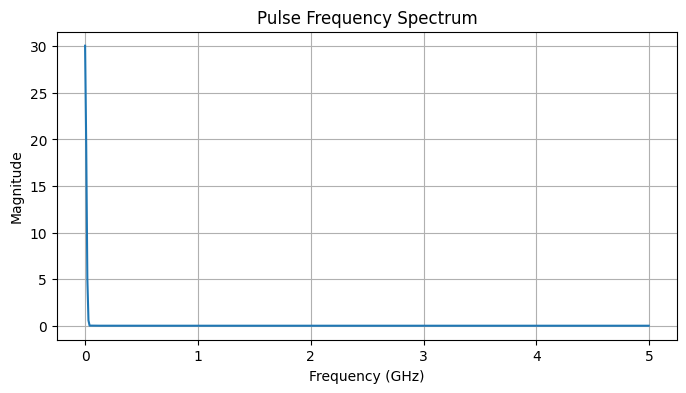

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(frequencies, spectrum)

plt.xlabel("Frequency (GHz)")
plt.ylabel("Magnitude")
plt.title("Pulse Frequency Spectrum")

plt.grid()
plt.show()

In [ ]:
number_of_qubits = 1
number_of_time_steps = len(tlist)

simulation_cost = number_of_qubits * number_of_time_steps

print("Number of Qubits:", number_of_qubits)
print("Number of Time Steps:", number_of_time_steps)
print("Simulation Cost Indicator:", simulation_cost)

Number of Qubits: 1
Number of Time Steps: 1001
Simulation Cost Indicator: 1001


In [ ]:
pulse_results = {
    "Number of Qubits": number_of_qubits,
    "Pulse Duration (ns)": actual_duration,
    "Pulse Bandwidth (GHz)": bandwidth,
    "Final Probability |0>": prob_0,
    "Final Probability |1>": prob_1,
    "Number of Time Steps": number_of_time_steps
}

pulse_results_df = pd.DataFrame(
    list(pulse_results.items()),
    columns=["Metric", "Value"]
)

print(pulse_results_df)

                  Metric        Value
0       Number of Qubits     1.000000
1    Pulse Duration (ns)   100.000000
2  Pulse Bandwidth (GHz)     0.000000
3  Final Probability |0>     0.004632
4  Final Probability |1>     0.995368
5   Number of Time Steps  1001.000000


In [ ]:
pulse_results_df.to_csv(
    "quantum_pulse_results.csv",
    index=False
)

print("Pulse results saved successfully!")

Pulse results saved successfully!


In [ ]:
from google.colab import files

files.download("quantum_pulse_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("========================================")
print("PULSE-LEVEL END-TO-END QUANTUM LEARNER")
print("========================================")

print("Dataset: Kaggle MNIST Digit Recognizer")
print("Total Images:", len(train))

print("Classical Model: Logistic Regression")
print("Quantum Model: PennyLane Variational Circuit")
print("Quantum Simulator: QuTiP")

print("----------------------------------------")
print("PULSE SIMULATION RESULTS")
print("----------------------------------------")

print("Qubits:", number_of_qubits)
print("Pulse Duration:", actual_duration, "ns")
print("Pulse Bandwidth:", bandwidth, "GHz")
print("Final State |0> Probability:", prob_0)
print("Final State |1> Probability:", prob_1)

print("----------------------------------------")
print("PROJECT EXECUTION COMPLETED")
print("----------------------------------------")

PULSE-LEVEL END-TO-END QUANTUM LEARNER
Dataset: Kaggle MNIST Digit Recognizer
Total Images: 42000
Classical Model: Logistic Regression
Quantum Model: PennyLane Variational Circuit
Quantum Simulator: QuTiP
----------------------------------------
PULSE SIMULATION RESULTS
----------------------------------------
Qubits: 1
Pulse Duration: 100.0 ns
Pulse Bandwidth: 0.0 GHz
Final State |0> Probability: 0.0046318344847765805
Final State |1> Probability: 0.9953681655152236
----------------------------------------
PROJECT EXECUTION COMPLETED
----------------------------------------


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Train and predict again for a consistent evaluation
from sklearn.linear_model import LogisticRegression

start_time = __import__("time").perf_counter()

final_classical_model = LogisticRegression(max_iter=1000)
final_classical_model.fit(X_train_pca, y_train)

classical_train_time = __import__("time").perf_counter() - start_time

start_time = __import__("time").perf_counter()
classical_predictions = final_classical_model.predict(X_test_pca)
classical_inference_time = __import__("time").perf_counter() - start_time

print("CLASSICAL MODEL RESULTS")
print("Accuracy:", accuracy_score(y_test, classical_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, classical_predictions))
print("Macro-F1:", f1_score(y_test, classical_predictions, average="macro"))
print("Confusion Matrix:")
print(confusion_matrix(y_test, classical_predictions))
print("Training Time:", classical_train_time, "seconds")
print("Inference Time:", classical_inference_time, "seconds")

CLASSICAL MODEL RESULTS
Accuracy: 0.5742857142857143
Balanced Accuracy: 0.5656382416066343
Macro-F1: 0.5509658641157918
Confusion Matrix:
[[678   0  29   6   4  41  32   0  37   0]
 [  0 877  26  10   0   4   0   3  16   1]
 [ 37  26 454  45  27  12 201   3  26   4]
 [ 23  12  42 620   8  57  10  11  83   4]
 [  8  12   3   0 498   0  51 126  11 105]
 [ 36  16  40 197  24 169  34  34 177  32]
 [ 28  18 206   0  31   0 512   0  32   0]
 [  2  23   2   2  65   8   6 566  31 175]
 [ 69  32  43 200   7 113  13  15 286  35]
 [  7  12   1   5 215  10  13 392  19 164]]
Training Time: 3.225413698000011 seconds
Inference Time: 0.012255564000042796 seconds


In [ ]:
from sklearn.metrics import roc_auc_score

# Binary test labels
y_true_binary = (y_test_q >= 5).astype(int)

# Use the probability scores from your existing quantum classifier.
# Replace this line with your existing quantum prediction function
# if its name is different.

y_score_binary = np.array([
    float(quantum_classifier(x, weights, bias))
    for x in X_test_q
])

y_score_binary = np.clip(y_score_binary, 0, 1)

y_pred_binary = (y_score_binary >= 0.5).astype(int)

print("QUANTUM BINARY CLASSIFICATION RESULTS")
print("Accuracy:", accuracy_score(y_true_binary, y_pred_binary))
print("Balanced Accuracy:", balanced_accuracy_score(y_true_binary, y_pred_binary))
print("Macro-F1:", f1_score(y_true_binary, y_pred_binary, average="macro"))
print("Confusion Matrix:")
print(confusion_matrix(y_true_binary, y_pred_binary))
print("AUROC:", roc_auc_score(y_true_binary, y_score_binary))

QUANTUM BINARY CLASSIFICATION RESULTS
Accuracy: 0.466
Balanced Accuracy: 0.5000805152979066
Macro-F1: 0.37250588716386757
Confusion Matrix:
[[213  17]
 [250  20]]
AUROC: 0.5994041867954911


In [ ]:
print("PULSE METRICS")
print("Pulse Duration:", actual_duration, "ns")
print("Control Bandwidth:", bandwidth, "GHz")

PULSE METRICS
Pulse Duration: 100.0 ns
Control Bandwidth: 0.0 GHz


In [ ]:
noise_level = 0.05

noisy_pulse = pulse * (
    1 + np.random.normal(0, noise_level, len(pulse))
)

def noisy_pulse_function(t, args):
    return np.interp(t, tlist, noisy_pulse)

H_noisy = [
    H0,
    [H1, noisy_pulse_function]
]

# Run noisy simulation (retains states since no e_ops is specified)
noisy_result = qt.sesolve(
    H_noisy,
    initial_state,
    tlist
)

# Rerun the ideal simulation without e_ops to retain the ideal state vectors
ideal_result = qt.sesolve(
    H,
    initial_state,
    tlist
)

ideal_final_state = ideal_result.states[-1]
noisy_final_state = noisy_result.states[-1]

fidelity = qt.fidelity(
    ideal_final_state,
    noisy_final_state
)

print("Control Noise Level:", noise_level * 100, "%")
print("State Fidelity under Noise:", fidelity)
print("Robustness (%):", fidelity * 100)

/usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


Control Noise Level: 5.0 %
State Fidelity under Noise: 0.9999962082020646
Robustness (%): 99.99962082020646


In [ ]:
# Qiskit circuit cost
print("QUANTUM COST")

print("Qubits:", qc.num_qubits)
print("Circuit Depth:", qc.depth())

# Statevector simulation does not use measurement shots.
print("Shots: Not applicable for analytic statevector simulation")

# PennyLane training configuration from previous cells
print("Quantum Training Epochs:", 10)
print("Training Samples:", 100)
print("Training Circuit Evaluations: Approximately", 10 * 100)

print("Quantum Test Samples:", len(X_test_q))
print("Inference Circuit Evaluations: Approximately", len(X_test_q))

print("Pulse Simulation Time Steps:", len(tlist))

QUANTUM COST
Qubits: 4
Circuit Depth: 4
Shots: Not applicable for analytic statevector simulation
Quantum Training Epochs: 10
Training Samples: 100
Training Circuit Evaluations: Approximately 1000
Quantum Test Samples: 500
Inference Circuit Evaluations: Approximately 500
Pulse Simulation Time Steps: 1001


In [ ]:
final_report = {
    "Pulse Duration (ns)": actual_duration,
    "Control Bandwidth (GHz)": bandwidth,
    "Noise Robustness (%)": fidelity * 100,
    "Qubits": qc.num_qubits,
    "Circuit Depth": qc.depth(),
    "Training Time (seconds)": classical_train_time,
    "Inference Time (seconds)": classical_inference_time
}

final_report_df = pd.DataFrame(
    list(final_report.items()),
    columns=["Evaluation Metric", "Result"]
)

print(final_report_df)

final_report_df.to_csv(
    "Project_15_Final_Report.csv",
    index=False
)

          Evaluation Metric      Result
0       Pulse Duration (ns)  100.000000
1   Control Bandwidth (GHz)    0.000000
2      Noise Robustness (%)   99.999621
3                    Qubits    4.000000
4             Circuit Depth    4.000000
5   Training Time (seconds)    3.225414
6  Inference Time (seconds)    0.012256
